# Figure S4: Structure and velocity of baroclinic coastal trapped waves

## Only code but not data provided for supplementary figures

### The modal structures are computed using a toolbox developed by Brink (2018) based on the mean stratification in CONTROL and cross-shelf topography. The text file with inputs to redo the calculation is 'CTW_modes_config' 

Brink, K. (2018). Stable coastal-trapped waves with stratification, topography and mean flow [dataset].
In Woods Hole Open Access Server (WHOAS) at the MBLWHOI Library. doi: 10.1575/1912/
https://darchive.mblwhoilibrary.org/entities/publication/50dc38f7-de8f-545f-985d-4b01bcf7ed61


In [44]:
%matplotlib inline
import xarray as xr
import numpy as np
from collections import OrderedDict
from dask.distributed import Client
import sys
sys.path.append(
    "/g/data/e14/cs6673/Ross_salinity/Python_scripts_published/") 
from Info_definitions import (
    path_plots, path_data_published, path_control, exptdict,
    yearly_mean, shelf_mask_isobath)
import gsw
from pathlib import Path
import scipy.io

import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker
from matplotlib.offsetbox import AnchoredText

In [10]:
plt.rcParams['figure.dpi'] = 96
plt.rcParams["font.size"] = 12
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["xtick.labelsize"] = 12
plt.rcParams["ytick.labelsize"] = 12
plt.rcParams["lines.linewidth"] = 1.5
plt.rcParams["lines.markersize"] = 3
plt.rcParams['hatch.color'] = 'k'
plt.rcParams["savefig.facecolor"] = 'white'

In [4]:
client = Client()
client

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 41167 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/41167/status,
Dashboard: /proxy/41167/status,Workers: 7
Total threads: 28,Total memory: 251.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42855,Workers: 0
Dashboard: /proxy/41167/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39443,Total threads: 4
Dashboard: /proxy/34441/status,Memory: 35.88 GiB
Nanny: tcp://127.0.0.1:46289,


## Load data

In [5]:
def f(lat):
    '''Coriolis parameter'''
    return 2*(2*np.pi/(60*60*24))*np.sin(lat*np.pi/180) # 1/s

In [45]:
"""load modal structures"""
section = '165E'
vel_files = sorted(Path('/g/data/e14/cs6673/Ross_salinity/data_CTW/' + section).glob('ctw*_field.mat'))
p_files = sorted(Path('/g/data/e14/cs6673/Ross_salinity/data_CTW/' + section).glob('p*_field.mat'))
cn_files = sorted(Path('/g/data/e14/cs6673/Ross_salinity/data_CTW/' + section).glob('L*_wave.mat'))
ds_list = []


for i, file in enumerate(vel_files):
    mat_vel = scipy.io.loadmat(vel_files[i])
    mat_p = scipy.io.loadmat(p_files[i])
    mat_cn = scipy.io.loadmat(cn_files[i])

    dummy = xr.Dataset({'v': (('n','z_grid','x_grid'), mat_vel['v_real'][np.newaxis,:,:]/np.abs(mat_vel['v_real']).max()),
                     'w': (('n','z_grid','x_grid'), mat_vel['w'][np.newaxis,:,:]/np.abs(mat_vel['w']).max()),
                     'p': (('n','z_grid','x_grid'), mat_p['p'].transpose()[np.newaxis,:,:]/np.abs(mat_p['p']).max()),
                     'rho': (('n','z_grid','x_grid'), mat_vel['rho'].transpose()[np.newaxis,:,:]/np.abs(mat_vel['rho']).max()),
                     'cn':(('n'), mat_cn['cn'][0]),
                     'bn':(('n'), mat_cn['bn'][0]),
                     'ann':(('n'), mat_cn['ann'][0])},
                    coords={'z': (('z_grid','x_grid'),mat_vel['zgr'].transpose()),
                            'x': (('z_grid','x_grid'),mat_vel['xgr'].transpose()),
                            'n':[int(str(file)[-11])]})
    ds_list.append(dummy)

ctw = xr.concat(ds_list, dim='n')


In [13]:
%%time
ekey = 'ctrl'
start_time = '2150-01-01'
end_time = '2159-12-31'

e = exptdict[ekey]

# masks for land, shelf, area of wind perturbation and DSW area
ds_bathy = xr.open_dataset(path_data_published + 'Bathymetry_landmask.nc')
ht = ds_bathy.depth
land_mask = ds_bathy.land_mask
mask, shelf_mask = shelf_mask_isobath(land_mask, output_mask=True)


ds = xr.open_mfdataset(
    path_control + '/output*/ocean/ocean.nc', 
    decode_timedelta=False,
    chunks={'yt_ocean': '200MB', 'xt_ocean': '200MB',
            'yu_ocean': '200MB', 'xu_ocean': '200MB'}).sel(
    time=slice(start_time, end_time),
    yt_ocean=slice(-79, -69), xt_ocean=slice(-200, -85))

salt = yearly_mean(ds.salt.isel(time=slice(3))).mean('time')
e['salt'] = salt.where(np.isnan(ht) == False)

temp = yearly_mean(ds.temp.isel(
        time=slice(3))).mean('time') - 273.15
e['temp'] = temp.where(np.isnan(ht) == False)

# Calculation of the First baroclinic gravity wave speed based on
# N2 from T and S profiles following the code available at 
# https://ecjoliver.weebly.com/rossby-radius.html

lon = e['temp'].xt_ocean
lat = e['temp'].yt_ocean
depth = e['temp'].st_ocean

lat_3D = lat.expand_dims({"xt_ocean": len(lon)}, axis=-1).expand_dims(
    {"st_ocean": len(depth)}, axis=0)
lat_3D['xt_ocean'] = lon
lat_3D['st_ocean'] = depth

pres = gsw.p_from_z(-depth, lat)
pres_3D = pres.expand_dims({"xt_ocean": len(lon)}, axis=-1)
pres_3D['xt_ocean'] = lon

SA = gsw.SA_from_SP(e['salt'], pres, lon, lat)
CT = e['temp']
N2, p_N2 = gsw.Nsquared(SA, CT, pres_3D, lat_3D)

# Replace negative values at the shallowest depth (depth index 0) with 10e-8
N2[0, :, :] = np.where(N2[0, :, :] < 0, 10e-8, N2[0, :, :])

# Fix negative values of N2, following Chelton et al. (1998):
# Replace a negative value with the (pos) value at the next shallowest depth.
for k in range(1, N2.shape[0]):
    # Find negative values at the current depth
    neg_mask = N2[k, :, :] < 0
    
    # Replace negative values with the values from the next shallower depth
    N2[k, :, :][neg_mask] = N2[k - 1, :, :][neg_mask]

# Calculate c1, cR
N2 = np.where(np.isnan(N2), 0, N2)
# First baroclinic gravity wave speed [m/s]
c1 = -np.trapezoid(np.sqrt(N2), gsw.z_from_p(p_N2, lat_3D[:-1, :]), axis=0) / np.pi
c1 = np.where(np.isnan(SA[0, :]), np.nan, c1)
# Second baroclinic gravity wave speed [m/s]
c2 = -np.trapezoid(np.sqrt(N2), gsw.z_from_p(p_N2, lat_3D[:-1, :]), axis=0) / np.pi / 2
c2 = np.where(np.isnan(SA[0, :]), np.nan, c2)
# Rossby radius of deformation [m]
e['cR'] = c1 / np.abs(f(lat_3D[0, :].drop('st_ocean')))
e['c1'] = 0*e['cR'] + c1 # make it a DataArray
e['c2'] = 0*e['cR'] + c2 # make it a DataArray

CPU times: user 22 s, sys: 8.15 s, total: 30.2 s
Wall time: 38.7 s


<timed exec>:70: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.


## Plot

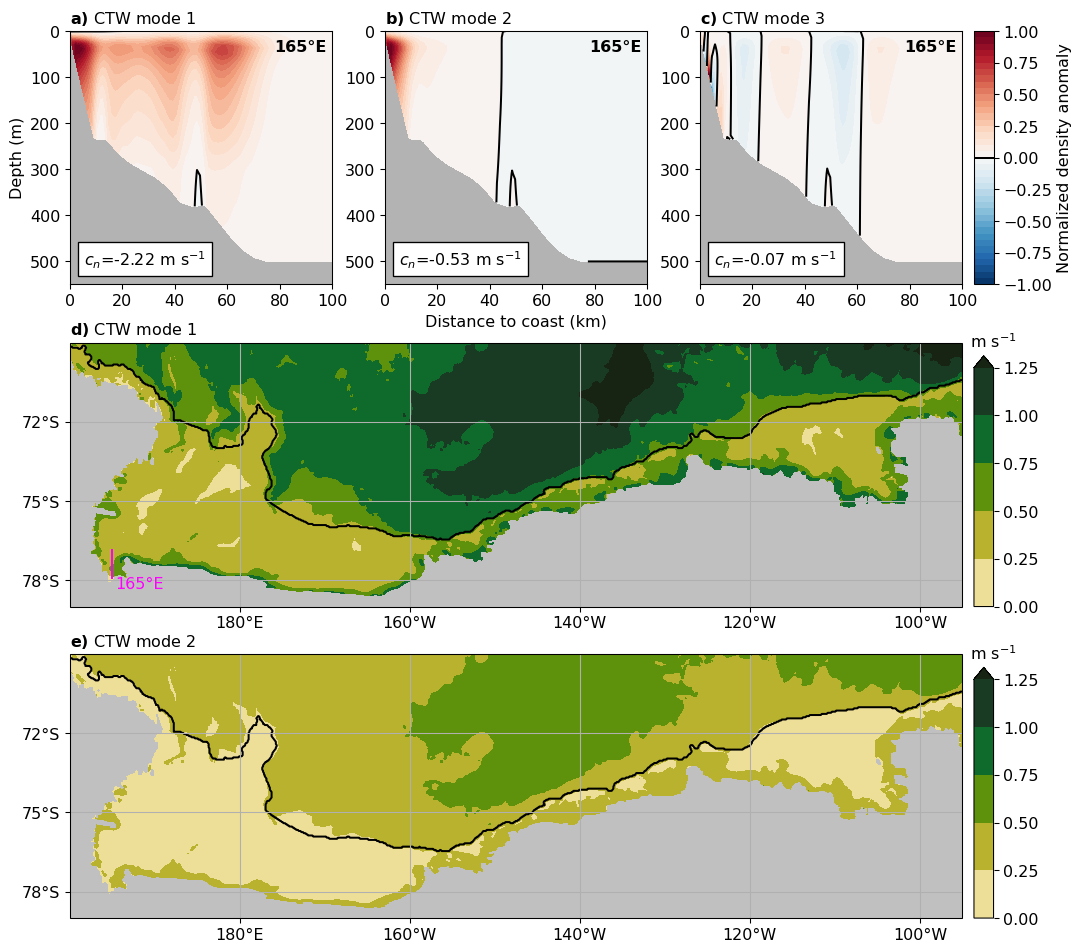

In [66]:
fig = plt.figure(figsize=(12, 12))
gs1 = fig.add_gridspec(3, 3, hspace=0.25, wspace=.2)
gs2 = fig.add_gridspec(3, 1, hspace=0.18, wspace=.2)


"""Section at 165 E"""
levels = np.arange(-1,1.001,0.05)
title = ['a)', 'b)', 'c)']
for i in range(len(title)):
    fig.add_subplot(gs1[0, i])
    ax = plt.gca()
    ax.set_facecolor([.7,.7,.7])
    im1 = ax.contourf(ctw.x, ctw.z*-1, ctw.rho.sel(n=i+1)*-1,
                           cmap='RdBu_r', levels=levels)
    cs = ax.contour(ctw.x, ctw.z*-1, ctw.rho.sel(n=i+1),
                           colors='k', levels=[0])
    at = AnchoredText("$c_n$=" + 
                      str(np.round(ctw.cn.isel(n=i).data/100,2)) + " m s$^{-1}$",
                      loc='lower left')
    ax.add_artist(at)
    ax.set_title(r"$\bf{"+title[i] +"}$" + " CTW mode " + str(i+1), loc='left')
    ax.text(.78, .92, "165°E", fontweight='bold', transform=plt.gca().transAxes)
    
    ax.set_ylim(550, 0)
    ax.set_xlim(0, 100)
    if i == 0:
        plt.ylabel('Depth (m)')
    if i == 1:
        plt.xlabel('Distance to coast (km)')

cax = fig.add_axes([ax.get_position().xmax+0.01, ax.get_position().ymin, 0.017,
                    ax.get_position().ymax-ax.get_position().ymin])
cbar = plt.colorbar(im1, cax=cax, ticks=np.arange(-1,1.1, 0.25))
cbar.add_lines(cs)
cbar.set_label('Normalized density anomaly')



"""Maps for mode 1 and mode 2"""
proj = ccrs.PlateCarree()
title = ['d)', 'e)']
for c in [1, 2]:
    fig.add_subplot(gs2[c, 0], projection=ccrs.PlateCarree(
        central_longitude=185))
    ax = plt.gca()
    
    ax.set_extent([160, 265, -79, -69])
    ax.contourf(land_mask.xt_ocean, land_mask.yt_ocean,
                land_mask, colors='silver', levels=[0.5, 2],
                zorder=2, transform=proj)
    plt.contour(shelf_mask.xt_ocean, shelf_mask.yt_ocean, shelf_mask,
                levels=[0, 1], colors = 'k',  transform=proj)
    gl = ax.gridlines(draw_labels=False)
    gl.xlocator = mticker.FixedLocator(
        [180, -160, -140, -120, -100])
    ax.set_xticks([180, -160, -140, -120, -100], crs=proj)
    ax.xaxis.set_major_formatter(LongitudeFormatter(
        dateline_direction_label=True))
    gl.ylocator = mticker.FixedLocator(
        np.arange(-81, -70, 3))
    ax.set_yticks(np.arange(-81, -70, 3), crs=proj)
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    plt.ylim(-79, None)
    ax.set_aspect('auto')
    ax.set_title(r"$\bf{"+title[c-1] +"}$" + " CTW mode " + str(c), loc='left')
    
    p = plt.contourf(e['c' + str(c)].xt_ocean, e['c' + str(c)].yt_ocean,
                     e['c' + str(c)],
                     levels=np.arange(0, 1.5, .25), cmap='cmo.speed',
                     extend='max', transform=proj)
    if c == 1:
        lon = -195  # 165E
        lat = slice(-77.9, -76.85)
        ax.plot([lon, lon], [lat.start, lat.stop], color='magenta',
                transform=proj)
        ax.text(lon+.4, lat.start-.4, "165°E", color='magenta', transform=proj)
        
    pos = ax.get_position()
    cax = plt.axes([pos.xmax+.01, pos.ymin,
                    0.017, .95*(pos.ymax-pos.ymin)])
    cb = plt.colorbar(p, cax=cax, orientation='vertical', extend='both')
    cb.ax.set_title('m s$^{-1}$', x=1)

plt.savefig(path_plots + 'FigS4.jpg', dpi=600, bbox_inches="tight")
plt.show()